# Thực nghiệm TLS — Nhiệt độ Quy Nhơn (ERA5)

Dữ liệu: nhiệt độ trung bình ngày ở độ cao 2 m, tái phân tích ERA5, lấy từ Open-Meteo Historical Weather API.

Nếu thư mục `data/` chưa có dữ liệu, chạy trước trong terminal:

```
py fetch_data.py
```

## 1. Import thư viện

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

NumPy: 1.26.4
Pandas: 2.2.3
Matplotlib: 3.9.4
Seaborn: 0.13.2


## 2. Đọc dữ liệu

In [2]:
DATA_DIR = Path("data")

df = pd.read_csv(DATA_DIR / "quy_nhon_era5_daily.csv", parse_dates=["date"])
meta = json.loads((DATA_DIR / "quy_nhon_era5_daily.json").read_text(encoding="utf-8"))

print("Nguồn:", meta["source"])
print(f"Ô lưới: {meta['grid_latitude']}°N, {meta['grid_longitude']}°E, độ cao {meta['elevation_m']} m")
print("Tải lúc (UTC):", meta["downloaded_at"])
df.head()

Nguồn: Open-Meteo Historical Weather API (ERA5 reanalysis)
Ô lưới: 13.75°N, 109.25°E, độ cao 1.0 m
Tải lúc (UTC): 2026-11-01T02:45:58+00:00


,date,temperature_2m_mean
0,2016-01-01,24.5
1,2016-01-02,24.2
2,2016-01-03,24.5
3,2016-01-04,25.3
4,2016-01-05,25.5


## 3. Kiểm tra dữ liệu

In [3]:
print(f"Số ngày: {len(df)} ({df['date'].min().date()} → {df['date'].max().date()})")
print("Giá trị thiếu:", df["temperature_2m_mean"].isna().sum())
print("Khoảng cách giữa các ngày liên tiếp:", df["date"].diff().dropna().dt.days.unique(), "ngày")
df["temperature_2m_mean"].describe()

Số ngày: 3951 (2016-01-01 → 2026-10-25)
Giá trị thiếu: 0
Khoảng cách giữa các ngày liên tiếp: [1] ngày


count    3951.000000
mean       27.292483
std         2.448688
min        19.600000
25%        25.400000
50%        27.500000
75%        29.300000
max        32.500000
Name: temperature_2m_mean, dtype: float64

## 4. Trực quan hóa chuỗi thời gian

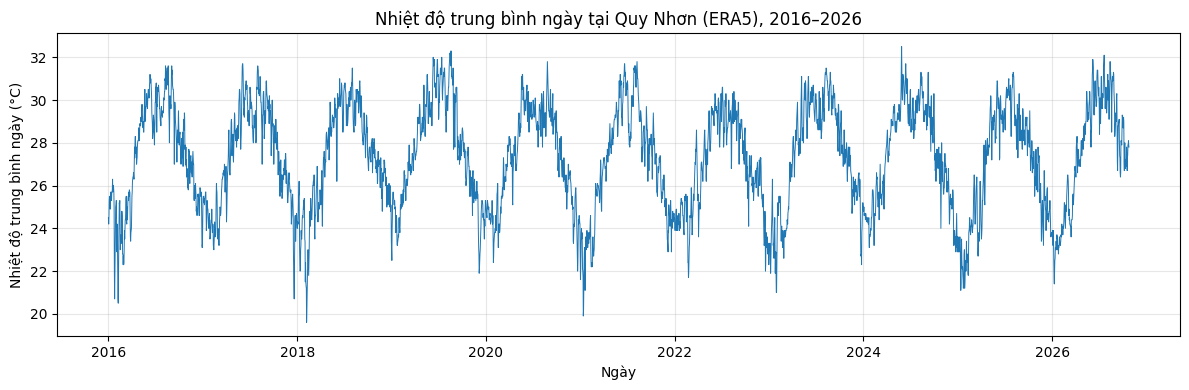

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"], df["temperature_2m_mean"], lw=0.7)
ax.set_xlabel("Ngày")
ax.set_ylabel("Nhiệt độ trung bình ngày (°C)")
ax.set_title("Nhiệt độ trung bình ngày tại Quy Nhơn (ERA5), 2016–2026")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Cài đặt TLS

Hệ số được sắp theo thứ tự $\boldsymbol\beta = [a_0, a_1, b_1, \ldots, a_K, b_K]^{\mathsf T}$, khớp với thứ tự cột của ma trận thiết kế $A$.

In [5]:
import warnings


def design_matrix(x, period, K):
    """Ma trận thiết kế với các cột [1, cos(ωx), sin(ωx), ..., cos(Kωx), sin(Kωx)]."""
    x = np.asarray(x, dtype=float).ravel()
    omega = 2 * np.pi / period
    columns = [np.ones_like(x)]
    for k in range(1, K + 1):
        columns.extend([np.cos(k * omega * x), np.sin(k * omega * x)])
    return np.column_stack(columns)


def fit_tls(x, y, period, K):
    """Ước lượng hệ số [a0, a1, b1, ..., aK, bK] bằng bình phương tối thiểu."""
    A = design_matrix(x, period, K)
    beta, _, rank, _ = np.linalg.lstsq(A, np.asarray(y, dtype=float), rcond=None)
    if rank < A.shape[1]:
        warnings.warn("Ma trận thiết kế bị thiếu hạng.")
    return beta


def fit_tls_cholesky(x, y, period, K):
    """Ước lượng hệ số bằng phân tích Cholesky của A^T A."""
    A = design_matrix(x, period, K)
    L = np.linalg.cholesky(A.T @ A)
    z = np.linalg.solve(L, A.T @ np.asarray(y, dtype=float))
    return np.linalg.solve(L.T, z)


def predict_tls(x, beta, period):
    """Giá trị dự đoán tại các điểm x."""
    K = (len(beta) - 1) // 2
    return design_matrix(x, period, K) @ beta


def coef_names(K):
    return ["a0"] + [f"{c}{k}" for k in range(1, K + 1) for c in ("a", "b")]


def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))


def mae(y, y_hat):
    return np.mean(np.abs(y - y_hat))

## 6. Chia dữ liệu theo thời gian

- **Tập khớp (train):** 01/01/2016 – 31/12/2024
- **Tập kiểm định (val):** 01/01/2025 – 31/12/2025, dùng để chọn $K$
- **Tập kiểm tra (test):** 01/01/2026 – 25/10/2026, chỉ dùng để đánh giá mô hình cuối cùng

Chia theo thời gian, không xáo trộn ngẫu nhiên, để mô hình không dùng thông tin tương lai. Biến $x$ là số ngày kể từ 01/01/2016, dùng chung một gốc cho cả ba tập; chu kỳ $T = 365{,}25$ ngày.

In [6]:
T = 365.25                              # chu kỳ năm (ngày)
VAL_START = pd.Timestamp("2025-01-01")
TEST_START = pd.Timestamp("2026-01-01")

x = (df["date"] - df["date"].iloc[0]).dt.days.to_numpy(dtype=float)  # số ngày kể từ 2016-01-01
y = df["temperature_2m_mean"].to_numpy()

is_train = (df["date"] < VAL_START).to_numpy()
is_val = ((df["date"] >= VAL_START) & (df["date"] < TEST_START)).to_numpy()
is_test = (df["date"] >= TEST_START).to_numpy()
x_train, y_train = x[is_train], y[is_train]
x_val, y_val = x[is_val], y[is_val]
x_test, y_test = x[is_test], y[is_test]

for name, mask in [("Tập khớp (train)", is_train), ("Tập kiểm định (val)", is_val), ("Tập kiểm tra (test)", is_test)]:
    dates = df["date"][mask]
    print(f"{name:20s}: {mask.sum():4d} ngày, {dates.min().date()} → {dates.max().date()}")

Tập khớp (train)    : 3288 ngày, 2016-01-01 → 2024-12-31
Tập kiểm định (val) :  365 ngày, 2025-01-01 → 2025-12-31
Tập kiểm tra (test) :  298 ngày, 2026-01-01 → 2026-10-25


## 7. Chọn số điều hòa K

Với mỗi $K$, khớp trên tập train và tính sai số trên tập val. Chọn $K$ có RMSE val nhỏ nhất; tập test không tham gia bước này.

In [7]:
rows = []
for k in range(1, 21):
    b = fit_tls(x_train, y_train, period=T, K=k)
    yh_train = predict_tls(x_train, b, period=T)
    yh_val = predict_tls(x_val, b, period=T)
    rows.append({
        "K": k,
        "Số hệ số": 2 * k + 1,
        "RMSE train": rmse(y_train, yh_train),
        "MAE train": mae(y_train, yh_train),
        "RMSE val": rmse(y_val, yh_val),
        "MAE val": mae(y_val, yh_val),
    })

results = pd.DataFrame(rows).set_index("K")
results.round(3)

,Số hệ số,RMSE train,MAE train,RMSE val,MAE val
K,,,,,
1,3,1.032,0.812,1.168,0.898
2,5,1.000,0.790,1.117,0.862
3,7,0.992,0.783,1.126,0.874
4,9,0.983,0.776,1.118,0.880
5,11,0.973,0.767,1.170,0.916
6,13,0.972,0.765,1.175,0.914
7,15,0.968,0.762,1.176,0.918
8,17,0.968,0.761,1.176,0.919
9,19,0.967,0.760,1.181,0.925


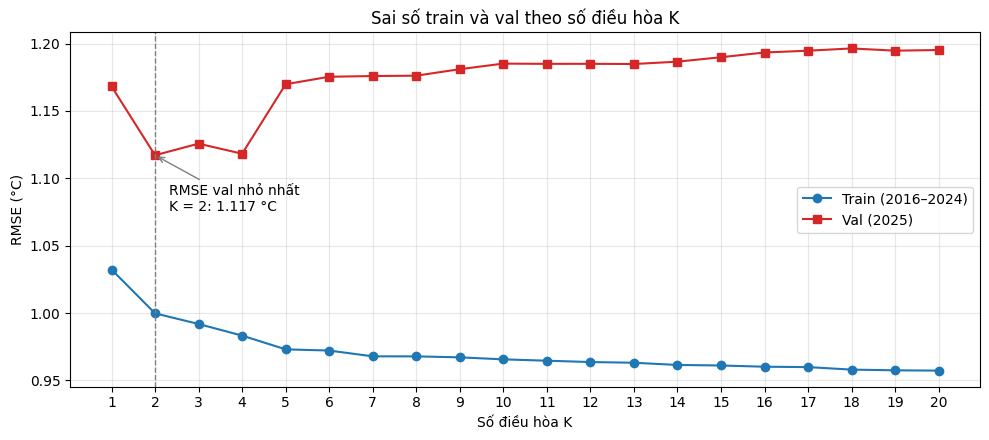

In [8]:
best_K = int(results["RMSE val"].idxmin())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(results.index, results["RMSE train"], marker="o", color="tab:blue", label="Train (2016–2024)")
ax.plot(results.index, results["RMSE val"], marker="s", color="tab:red", label="Val (2025)")
ax.axvline(best_K, color="gray", ls="--", lw=1)
ax.annotate(
    f"RMSE val nhỏ nhất\nK = {best_K}: {results.loc[best_K, 'RMSE val']:.3f} °C",
    xy=(best_K, results.loc[best_K, "RMSE val"]),
    xytext=(10, -40), textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="gray"),
)
ax.set_xticks(results.index)
ax.set_xlabel("Số điều hòa K")
ax.set_ylabel("RMSE (°C)")
ax.set_title("Sai số train và val theo số điều hòa K")
ax.grid(alpha=0.3)
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

## 8. Khớp mô hình với K đã chọn và đánh giá

Khớp trên tập train với $K$ chọn ở mục 7, sau đó đánh giá trên cả ba tập.

In [9]:
K = best_K
beta = fit_tls(x_train, y_train, period=T, K=K)
beta_cholesky = fit_tls_cholesky(x_train, y_train, period=T, K=K)
y_hat_train = predict_tls(x_train, beta, period=T)
y_hat_val = predict_tls(x_val, beta, period=T)
y_hat_test = predict_tls(x_test, beta, period=T)

print("Hệ số ước lượng:")
print(pd.DataFrame({"SVD": beta, "Cholesky": beta_cholesky}, index=coef_names(K)).round(4).to_string())

pd.DataFrame(
    {
        "RMSE (°C)": [rmse(y_train, y_hat_train), rmse(y_val, y_hat_val), rmse(y_test, y_hat_test)],
        "MAE (°C)": [mae(y_train, y_hat_train), mae(y_val, y_hat_val), mae(y_test, y_hat_test)],
    },
    index=["Train (2016–2024)", "Val (2025)", "Test (01–10/2026)"],
).round(3)

Hệ số ước lượng:
        SVD  Cholesky
a0  27.3169   27.3169
a1  -2.9632   -2.9632
b1  -0.7927   -0.7927
a2  -0.1797   -0.1797
b2  -0.3161   -0.3161


,RMSE (°C),MAE (°C)
Train (2016–2024),1.000,0.790
Val (2025),1.117,0.862
Test (01–10/2026),0.898,0.717


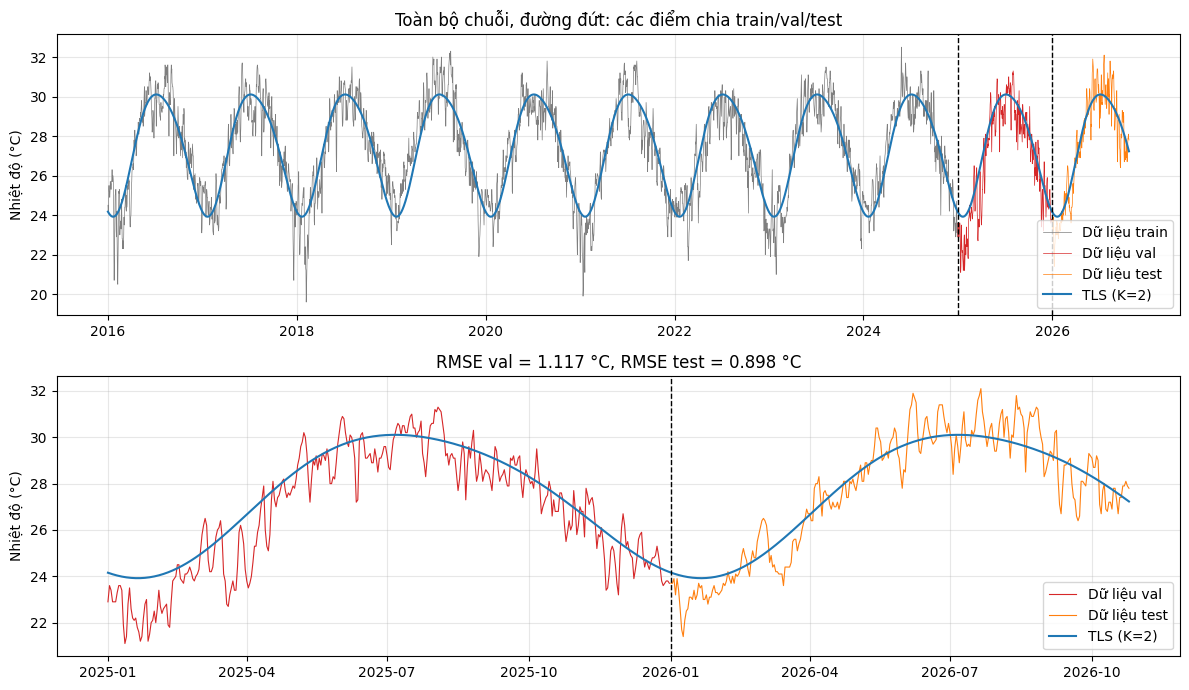

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
dates_train, dates_val, dates_test = df["date"][is_train], df["date"][is_val], df["date"][is_test]

# Toàn bộ chuỗi
ax = axes[0]
ax.plot(dates_train, y_train, lw=0.5, color="tab:gray", label="Dữ liệu train")
ax.plot(dates_val, y_val, lw=0.5, color="tab:red", label="Dữ liệu val")
ax.plot(dates_test, y_test, lw=0.5, color="tab:orange", label="Dữ liệu test")
ax.plot(df["date"], predict_tls(x, beta, period=T), lw=1.5, color="tab:blue", label=f"TLS (K={K})")
for split in (VAL_START, TEST_START):
    ax.axvline(split, color="k", ls="--", lw=1)
ax.set_title("Toàn bộ chuỗi, đường đứt: các điểm chia train/val/test")

# Phóng to tập val và test
ax = axes[1]
ax.plot(dates_val, y_val, lw=0.8, color="tab:red", label="Dữ liệu val")
ax.plot(dates_test, y_test, lw=0.8, color="tab:orange", label="Dữ liệu test")
ax.plot(df["date"][is_val | is_test], predict_tls(x[is_val | is_test], beta, period=T), lw=1.5, color="tab:blue", label=f"TLS (K={K})")
ax.axvline(TEST_START, color="k", ls="--", lw=1)
ax.set_title(f"RMSE val = {rmse(y_val, y_hat_val):.3f} °C, RMSE test = {rmse(y_test, y_hat_test):.3f} °C")

for ax in axes:
    ax.set_ylabel("Nhiệt độ (°C)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 9. Phân phối sai số trên tập test

Phần dư $r_i = y_i - \hat y_i$ của mô hình ở mục 8 trên tập test (dương: thực tế nóng hơn mô hình), kèm đường ước lượng mật độ nhân (KDE).

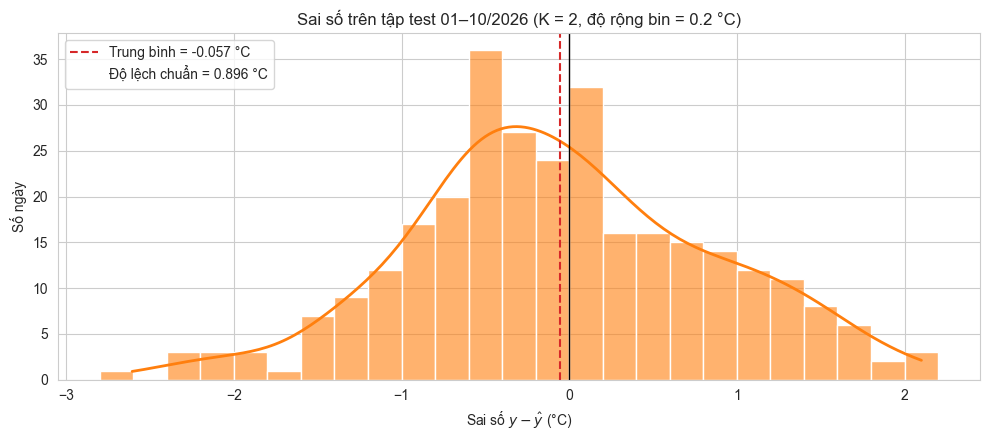

In [11]:
BIN_WIDTH = 0.2  # °C
res_test = y_test - y_hat_test

# Căn mép bin theo bội số của BIN_WIDTH (0 nằm đúng trên một mép bin)
bin_range = (
    np.floor(res_test.min() / BIN_WIDTH) * BIN_WIDTH,
    np.ceil(res_test.max() / BIN_WIDTH) * BIN_WIDTH,
)

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.histplot(
        res_test, binwidth=BIN_WIDTH, binrange=bin_range, kde=True, ax=ax,
        color="tab:orange", alpha=0.6, edgecolor="white", linewidth=1,
        line_kws={"lw": 2},
    )
    ax.axvline(0, color="k", lw=1)
    ax.axvline(res_test.mean(), color="tab:red", ls="--", lw=1.5,
               label=f"Trung bình = {res_test.mean():+.3f} °C")
    ax.plot([], [], " ", label=f"Độ lệch chuẩn = {res_test.std():.3f} °C")
    ax.set_xlabel("Sai số $y - \\hat y$ (°C)")
    ax.set_ylabel("Số ngày")
    ax.set_title(f"Sai số trên tập test 01–10/2026 (K = {K}, độ rộng bin = {BIN_WIDTH} °C)")
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.show()